# Abdelhafidh Mahouel Notebook
# P2: Text Preprocessing - Technical Modification

- Author: [Abdelhafidh Mahouel](https://github.com/AbdelhafidhMahouel/)
- Repository: [nlp-02-text-preprocessing](https://github.com/AbdelhafidhMahouel/nlp-02-text-preprocessing/)
- Purpose: Change one preprocessing decision (the stop word list) and compare the results with the original example
- Date: 2026-11

**Modification:** the original example removes 27 stop words.
This notebook adds 18 more common English function words
(such as *may*, *many*, *some*, *very*, *can*, *this*)
and compares token counts, top tokens, and charts before and after the change.
Everything else (data, lowercasing, punctuation removal, minimum token length) stays the same.

## Section 1. Setup and Imports

In [9]:
# Section 1 Python cell.

# Imports at the top of the file
# REQ: External packages must be defined in pyproject.toml
# REQ: External packages must be installed in the environment using `uv sync` command
# REQ: External packages used in this notebook must be imported here

from pathlib import Path
import re

import matplotlib.pyplot as plt
import polars as pl

print("Imports complete.")

Imports complete.


## Section 2. Read the Text Data

Same example data as the original project.

In [10]:
# Section 2 Python cell

# In notebooks, start with the current working directory
# where the notebook is located.
NOTEBOOKS_PATH: Path = Path.cwd()
ROOT_PATH: Path = NOTEBOOKS_PATH.parent

DATA_PATH: Path = ROOT_PATH / "data"
NOTEBOOKS_PATH: Path = ROOT_PATH / "notebooks"
SCRIPTS_PATH: Path = ROOT_PATH / "scripts"

# Choose a text file to analyze.
# Each line is treated as one text record.
input_path: Path = DATA_PATH / "text_data.txt"

# Read all lines from the file.
text_list: list[str] = input_path.read_text(encoding="utf-8").splitlines()

# Remove blank lines.
text_list = [line.strip() for line in text_list if line.strip()]

print("Data loaded successfully.")
print(f"Loaded {len(text_list):,} text records.")

# Combine all text rows into one large string for simple preprocessing.
raw_text: str = " ".join(text_list)

print(f"Raw text length: {len(raw_text):,} characters")
print("First 500 characters of raw text:")
print(raw_text[:500])

Data loaded successfully.
Loaded 5 text records.
Raw text length: 375 characters
First 500 characters of raw text:
Natural Language Processing helps computers understand human language. Text preprocessing removes punctuation, converts text to lowercase, and splits text into tokens. Some words appear very frequently in language and may be removed as stop words. Python provides many tools for working with text data. Web pages emails and social media posts are common sources of text data.


## Section 3. Tokenize, Lowercase, and Remove Punctuation

These steps are unchanged from the original.

In [11]:
raw_tokens: list[str] = raw_text.split()
count_of_raw_tokens: int = len(raw_tokens)

lower_text: str = raw_text.lower()
no_punct_text: str = re.sub(r"[^a-z0-9\s]", " ", lower_text)
tokens_no_punct: list[str] = no_punct_text.split()
count_of_tokens_no_punct: int = len(tokens_no_punct)

print(f"Total raw tokens: {count_of_raw_tokens:,}")
print(f"Total tokens after punctuation removal: {count_of_tokens_no_punct:,}")

Total raw tokens: 57
Total tokens after punctuation removal: 57


## Section 4. The Modification: Expand the Stop Word List

`STOP_WORDS` is the original list.
`ADDED_STOP_WORDS` holds the new words.
Both versions are applied to the same tokens so they can be compared fairly.

In [12]:
# Original stop word list from the example.
STOP_WORDS: set[str] = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "but",
    "by",
    "for",
    "from",
    "has",
    "have",
    "in",
    "is",
    "it",
    "its",
    "of",
    "on",
    "or",
    "that",
    "the",
    "to",
    "was",
    "were",
    "will",
    "with",
}

# MODIFICATION: additional common function words.
ADDED_STOP_WORDS: set[str] = {
    "can",
    "may",
    "many",
    "some",
    "very",
    "such",
    "this",
    "these",
    "those",
    "into",
    "than",
    "also",
    "their",
    "they",
    "them",
    "which",
    "what",
    "more",
}

MODIFIED_STOP_WORDS: set[str] = STOP_WORDS | ADDED_STOP_WORDS


def clean(tokens: list[str], stop_words: set[str]) -> list[str]:
    """Keep tokens longer than 2 characters that are not stop words."""
    return [t for t in tokens if len(t) > 2 and t not in stop_words]


original_tokens: list[str] = clean(tokens_no_punct, STOP_WORDS)
modified_tokens: list[str] = clean(tokens_no_punct, MODIFIED_STOP_WORDS)

removed_by_change: list[str] = sorted(set(original_tokens) - set(modified_tokens))

print(f"Original stop words: {len(STOP_WORDS)}")
print(f"Modified stop words: {len(MODIFIED_STOP_WORDS)}")
print(f"Cleaned tokens (original): {len(original_tokens)}")
print(f"Cleaned tokens (modified): {len(modified_tokens)}")
print(f"Words removed only by the modification: {removed_by_change}")

Original stop words: 27
Modified stop words: 45
Cleaned tokens (original): 46
Cleaned tokens (modified): 41
Words removed only by the modification: ['into', 'many', 'may', 'some', 'very']


## Section 5. Compare Token Counts

In [13]:
summary_df: pl.DataFrame = pl.DataFrame(
    {
        "stage": [
            "raw tokens",
            "after punctuation removal",
            "after stop words (original)",
            "after stop words (modified)",
        ],
        "count": [
            count_of_raw_tokens,
            count_of_tokens_no_punct,
            len(original_tokens),
            len(modified_tokens),
        ],
    }
)
print(summary_df)

shape: (4, 2)
┌─────────────────────────────┬───────┐
│ stage                       ┆ count │
│ ---                         ┆ ---   │
│ str                         ┆ i64   │
╞═════════════════════════════╪═══════╡
│ raw tokens                  ┆ 57    │
│ after punctuation removal   ┆ 57    │
│ after stop words (original) ┆ 46    │
│ after stop words (modified) ┆ 41    │
└─────────────────────────────┴───────┘


## Section 6. Compare the Most Frequent Tokens

In [14]:
def top_tokens(tokens: list[str], n: int = 10) -> pl.DataFrame:
    """Return the n most frequent tokens with their counts."""
    return (
        pl.DataFrame({"token": tokens})
        .group_by("token")
        .len()
        .sort(["len", "token"], descending=[True, False])
        .head(n)
    )


original_top: pl.DataFrame = top_tokens(original_tokens)
modified_top: pl.DataFrame = top_tokens(modified_tokens)

print("Top 10 cleaned tokens (original):")
print(original_top)
print("Top 10 cleaned tokens (modified):")
print(modified_top)

Top 10 cleaned tokens (original):
shape: (10, 2)
┌────────────┬─────┐
│ token      ┆ len │
│ ---        ┆ --- │
│ str        ┆ u64 │
╞════════════╪═════╡
│ text       ┆ 5   │
│ language   ┆ 3   │
│ data       ┆ 2   │
│ words      ┆ 2   │
│ appear     ┆ 1   │
│ common     ┆ 1   │
│ computers  ┆ 1   │
│ converts   ┆ 1   │
│ emails     ┆ 1   │
│ frequently ┆ 1   │
└────────────┴─────┘
Top 10 cleaned tokens (modified):
shape: (10, 2)
┌────────────┬─────┐
│ token      ┆ len │
│ ---        ┆ --- │
│ str        ┆ u64 │
╞════════════╪═════╡
│ text       ┆ 5   │
│ language   ┆ 3   │
│ data       ┆ 2   │
│ words      ┆ 2   │
│ appear     ┆ 1   │
│ common     ┆ 1   │
│ computers  ┆ 1   │
│ converts   ┆ 1   │
│ emails     ┆ 1   │
│ frequently ┆ 1   │
└────────────┴─────┘


## Section 7. Visualize the Change

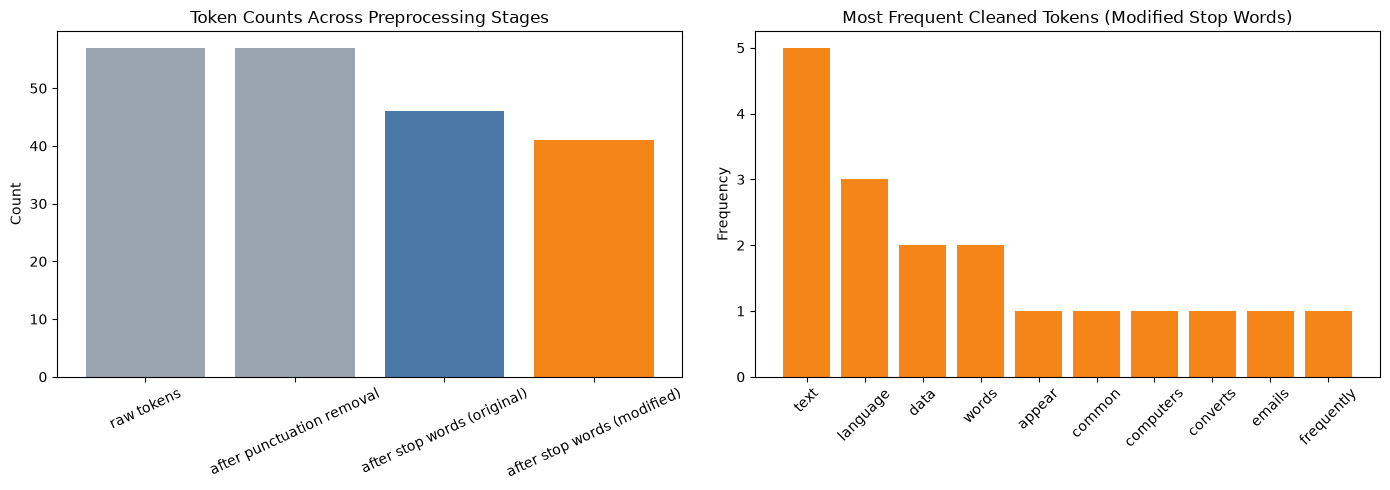

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    summary_df["stage"],
    summary_df["count"],
    color=["#9aa5b1", "#9aa5b1", "#4c78a8", "#f58518"],
)
axes[0].set_title("Token Counts Across Preprocessing Stages")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", labelrotation=25)

axes[1].bar(modified_top["token"], modified_top["len"], color="#f58518")
axes[1].set_title("Most Frequent Cleaned Tokens (Modified Stop Words)")
axes[1].set_ylabel("Frequency")
axes[1].tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

## Section 8. What Changed and Why

- Expanding the stop word list removed 5 extra low-meaning tokens (*into*, *many*, *may*, *some*, *very*),
  so the cleaned token count dropped from 46 to 41 while the top tokens stayed the same.
- The top tokens (*text*, *language*, *data*, *words*) are content words, so they were not affected.
- On a small dataset the effect is modest, but on a larger corpus these function words would appear
  often and could crowd out meaningful words in the frequency chart.
- Tradeoff: every word added to a stop list is a decision. Words like *not* or *very* can carry
  meaning in tasks such as sentiment analysis, so the right list depends on the analytical goal.